In [171]:
#importing packages
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import statsmodels.api as sm
import pandas
from sklearn.preprocessing import OneHotEncoder
from scipy import stats
from sklearn.model_selection import train_test_split, cross_val_score , KFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression , LogisticRegression ,RidgeCV,LassoCV
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error ,accuracy_score,confusion_matrix,classification_report
from sklearn import metrics



In [ ]:


#read primary dataset
df = pd.read_csv("social_media_usagefnl.csv")

Saving social_media_usagefnl.csv to social_media_usagefnl (1).csv


In [ ]:

#read secondary dataset
dfs = pd.read_csv("Screentime_v_Mental_Health_Datasetf.csv")

Saving Screentime_v_Mental_Health_Datasetf.csv to Screentime_v_Mental_Health_Datasetf (1).csv


In [88]:
#converting categorical independant variable to numerical coding

df['average_daily_usage'].replace(['Less than an Hour', 'Between 1 and 2 hours','Between 2 and 3 hours','Between 3 and 4 hours', 'Between 4 and 5 hours','More than 5 hours'],
                        [0,1,2,3,4,5], inplace=True)

df['gender'] = np.where((df['gender'] == 'Male') | (df['gender'] == 'Female'), df['gender'], 'Other')

df['gender'].replace(['Male', 'Female','Other'],
                        [0,1,2], inplace=True)



/tmp/ipython-input-1808166062.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['average_daily_usage'].replace(['Less than an Hour', 'Between 1 and 2 hours','Between 2 and 3 hours','Between 3 and 4 hours', 'Between 4 and 5 hours','More than 5 hours'],
/tmp/ipython-input-1808166062.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object o

,Timestamp,age,gender,relationship_status,occupation,social_media_use,average_daily_usage,usage_with_no_purpose_score,distraction_when_busy_score,restlessness_without_sm_score,distractability_score,worry_score,difficulty_concentrating_score,comparison_rate,compariosn_reflection,validation_need,depression_rate,activity_interest_changes,sleep_issue_rate
0,4/18/2022 19:18:47,21.0,2,In a relationship,University Student,Yes,2,5,3,2,5,2,5,2,3,2,5,4,5
1,4/18/2022 19:19:28,21.0,2,Single,University Student,Yes,5,4,3,2,4,5,4,5,1,1,5,4,5
2,4/18/2022 19:25:59,21.0,2,Single,University Student,Yes,3,3,2,1,2,5,4,3,3,1,4,2,5
3,4/18/2022 19:29:43,21.0,2,Single,University Student,Yes,5,4,2,1,3,5,3,5,1,2,4,3,2
4,4/18/2022 19:33:31,21.0,2,Single,University Student,Yes,2,3,5,4,4,5,5,3,3,3,4,4,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
476,5/21/2022 23:38:28,24.0,2,Single,Salaried Worker,Yes,2,3,4,3,4,3,4,4,2,4,3,4,4
477,5/22/2022 0:01:05,26.0,2,Married,Salaried Worker,Yes,1,2,1,2,3,4,4,4,2,4,4,4,1
478,5/22/2022 10:29:21,29.0,2,Married,Salaried Worker,Yes,2,3,3,4,3,2,3,3,3,4,2,2,2
479,7/14/2022 19:33:47,21.0,2,Single,University Student,Yes,2,2,3,2,3,3,2,2,3,4,4,5,4


Mean Squared Error: 1.5197890940645815
R-squared: 0.07576941662011072
Mean Absolute Error: 1.0460728168238476
Coefficient/slope: [[0.4416569]]
Intercept: [3.21614583]


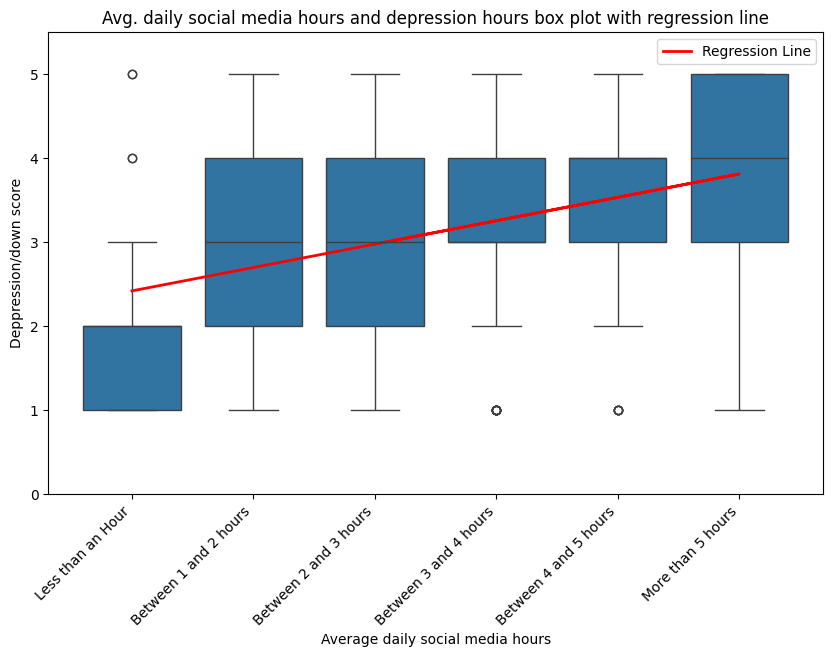

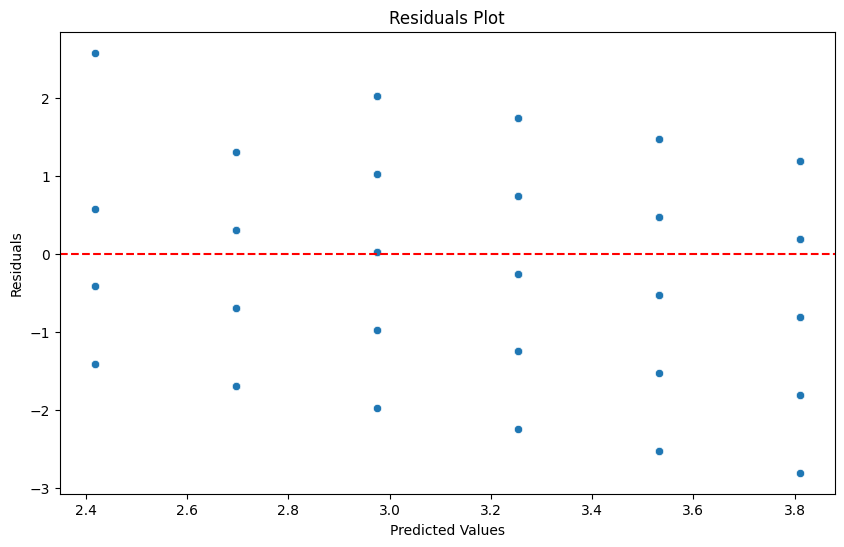

In [176]:
#assigning independant variable
X=df[['average_daily_usage']]
#assignning dependant variables relevant to the study
y=df[['depression_rate']]
#splitting data set 80% training 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = LinearRegression()
model.fit(X_train, y_train)


y_pred = model.predict(X_test)
#calculating mse,r2, mae
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
#print results including slope and intercept
print("Mean Squared Error:", mse)
print("R-squared:", r2)
print("Mean Absolute Error:", mae)
print("Coefficient/slope:", model.coef_)
print("Intercept:", model.intercept_)


plt.figure(figsize=(10, 6)) # Optional: set figure size
sns.boxplot(x='average_daily_usage', y='depression_rate', data=df)

plt.ylim(0, 5.5)


X_scaled_full = scaler.transform(X)

y_full_pred = model.predict(X_scaled_full)
# add regression line
plt.plot(X, y_full_pred, color='red', linewidth=2, label='Regression Line')

plt.xticks([0,1,2,3,4,5], ['Less than an Hour', 'Between 1 and 2 hours','Between 2 and 3 hours','Between 3 and 4 hours', 'Between 4 and 5 hours','More than 5 hours'])
plt.xticks(rotation=45, ha='right')
# Add labels and title
plt.xlabel('Average daily social media hours')
plt.ylabel('Deppression/down score')
plt.title('Avg. daily social media hours and depression hours box plot with regression line')
plt.legend()

plt.show()

residuals = y_test - y_pred
plt.figure(figsize=(10, 6))

sns.scatterplot(x=y_pred.flatten(), y=residuals.values.flatten())
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.title('Residuals Plot')
plt.show()

Mean Squared Error: 1.8006438971342345
R-squared: 0.11277203380686733
Mean Absolute Error: 1.1518883098114798
Coefficient/slope: [[0.48014717]
 [0.19836404]
 [0.43913021]]
Intercept: [3.32291667 3.19270833 3.24479167]


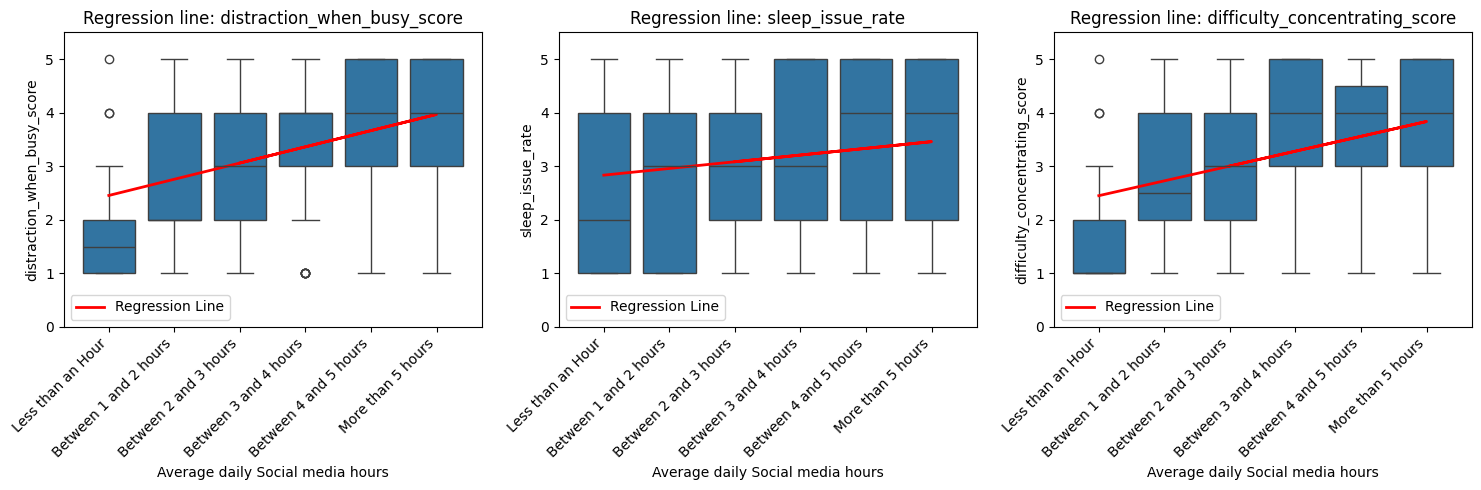

In [163]:
#assigning independant variable
X=df[['average_daily_usage']]
#assignning dependant variables relevant to the study
y=df[['distraction_when_busy_score','sleep_issue_rate','difficulty_concentrating_score']]
#splitting data set 80% training 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
#calculating mse,r2, mae
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
#print results including slope and intercept
print("Mean Squared Error:", mse)
print("R-squared:", r2)
print("Mean Absolute Error:", mae)
print("Coefficient/slope:", model.coef_)
print("Intercept:", model.intercept_)


# Get all y columms
target_columns = y.columns

#scaling values
X_scaled_full = scaler.transform(X)
y_full_pred = model.predict(X_scaled_full)

plt.figure(figsize=(15, 5)) # Adjust figure size for three subplots
#plot each y feature
for i, col in enumerate(target_columns):
    plt.subplot(1, len(target_columns), i + 1)

    sns.boxplot(x='average_daily_usage', y=y[col], data=df)
    plt.plot(X['average_daily_usage'], y_full_pred[:, i], color='red', linewidth=2, label='Regression Line')

    plt.xticks([0,1,2,3,4,5], ['Less than an Hour', 'Between 1 and 2 hours','Between 2 and 3 hours','Between 3 and 4 hours', 'Between 4 and 5 hours','More than 5 hours'])
    plt.xticks(rotation=45, ha='right')
    plt.xlabel('Average daily Social media hours')
    plt.ylabel(col)
    plt.title(f'Regression line: {col}')
    plt.ylim(0, 5.5)
    plt.legend()

# Show plots.
plt.tight_layout()
plt.show()

In [136]:
#assigning independant variable
X=df[['average_daily_usage','age','gender']]
#assignning dependant variables relevant to the study
y=df[['depression_rate']]
#splitting data set 80% training 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = LinearRegression()
model.fit(X_train, y_train)


y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
print("Mean Squared Error:", mse)
print("R-squared:", r2)
print("Mean Absolute Error:", mae)
print("Coefficient/slope:", model.coef_)
print("Intercept:", model.intercept_)

Mean Squared Error: 1.5205723101041675
R-squared: 0.07529311881010137
Mean Absolute Error: 1.0382773454558831
Coefficient/slope: [[ 0.33169003 -0.30903589  0.        ]]
Intercept: [3.21614583]


In [133]:
#converting to numerical representation
dfs['screentime'].replace(['Less than 1 hour','1 hour', '2 hours','3 hours','4 or more hours'],
                        [0,1,2,3,4], inplace=True)

In [134]:
dfs['mental_health_treatment'].replace(['Does Not Need Treatment','Needs Treatment'],
                        [0,1], inplace=True)

#dfs['mental_health_treatment'].replace([0,1],
                        #['Does Not Need Treatment','Needs Treatment'], inplace=True)

In [161]:
#assigning independant variable
Xs=dfs[['screentime']]
#assignning dependant variables relevant to the study
ys=dfs[['mental_health_treatment']]

X_trains, X_tests, y_trains, y_tests = train_test_split(Xs, ys, test_size=0.2, random_state=0)

scaler = StandardScaler()
X_trains = scaler.fit_transform(X_trains)
X_tests = scaler.transform(X_tests)


model = LogisticRegression(class_weight='balanced', random_state=0)


model.fit(X_trains, y_trains.values.ravel())

y_preds = model.predict(X_tests)
cnf_matrix = metrics.confusion_matrix(y_tests, y_preds)
print(cnf_matrix)

target_names = ['Does Not Need Treatment', 'Needs Treatment']
print(classification_report(y_tests, y_preds, target_names=target_names))

[[2182 1311]
 [ 399  463]]
                         precision    recall  f1-score   support

Does Not Need Treatment       0.85      0.62      0.72      3493
        Needs Treatment       0.26      0.54      0.35       862

               accuracy                           0.61      4355
              macro avg       0.55      0.58      0.53      4355
           weighted avg       0.73      0.61      0.65      4355

